<a href="https://colab.research.google.com/github/APP155-Jarlego/APP155-JARLEGO/blob/main/JARLEGO%2C_Samantha_Lab_09_App_Phy_155.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0.3 0.25927505818411367 0.25927505818411367 0.3076923076923077


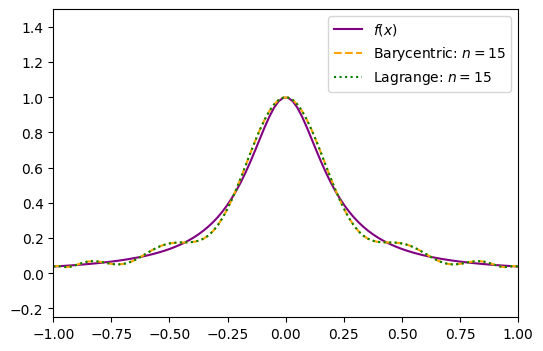

Largest Difference Betweeen the Two Methods: 6.661338147750939e-16


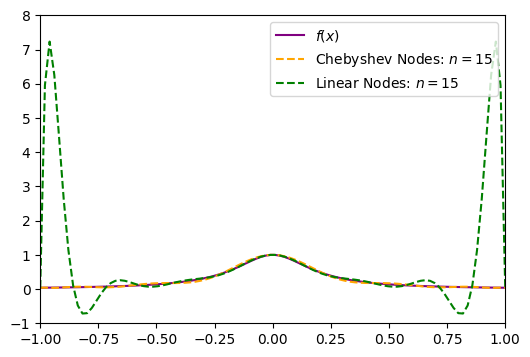

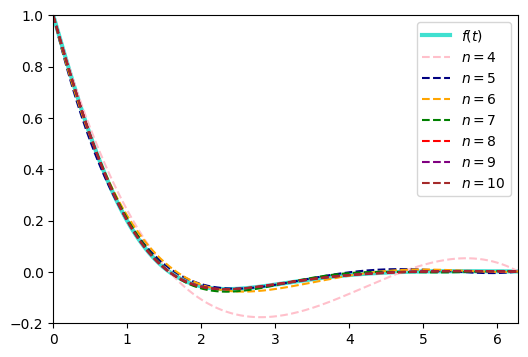

2 0.7534689765168908
3 0.3642353547906985
4 0.12410786782064792
5 0.02668105030677792
6 0.024949169243048033
7 0.009918796848289169
8 0.0022606294227172086
9 0.00022101142692176196
10 7.498727955163043e-05
11 2.7393506203610835e-05
12 4.913062601516471e-06
13 3.988206846994302e-07
14 5.53746805700972e-08
15 1.922580252639028e-08
16 2.8174558935889493e-09
17 1.9168316239825955e-10
18 1.4486960242532376e-11
19 4.816813614638704e-12
20 5.967865090994451e-13


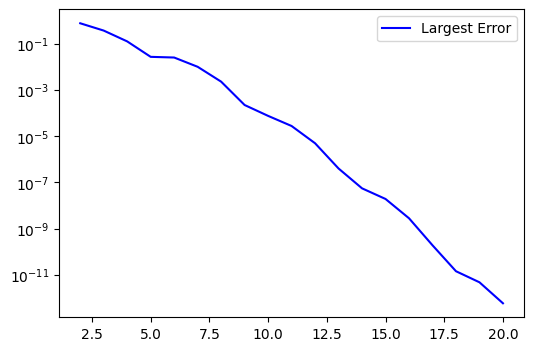

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#Part 1
def f(x):
    return 1/(1+25*x**2)

def generatedata(n,f,nodes="cheb"):
    if nodes=="cheb":
        dataxs = -np.cos(np.linspace(0,np.pi,n))
    else:
        dataxs = np.linspace(-1,1,n)
    datays= f(dataxs)
    return dataxs, datays

def weights(dataxs):
    n = dataxs.size
    ws = np.ones(n)
    for k in range(n):
        for j in range(n):
            if j == k:
                continue
            ws[k] *= (dataxs[k]-dataxs[j])
    return 1/ws

def bary(dataxs,datays,ws,x):
    k = np.where(x == dataxs)[0]
    if k.size == 0:
        nume = np.sum(ws*datays/(x-dataxs))
        denom = np.sum(ws/(x-dataxs))
        val = nume/denom
    else:
        val = datays[k[0]]
    return val

def lagrange(dataxs,datays,x):
    n = dataxs.size
    px = 0.
    for k in range(n):
        Lk = 1.
        for j in range(n):
            if j == k:
                continue
            Lk *= (x-dataxs[j])/(dataxs[k]-dataxs[j])
        px += datays[k]*Lk
    return px

#Calculating the case for n=15 nodes & x=0.3
#(w/ and w/o barycentric)

dataxs, datays = generatedata(15,f)
ws = weights(dataxs)
x = 0.3
pofx_bary = bary(dataxs, datays, ws, x)
pofx_lag = lagrange(dataxs, datays, x)
print(x, pofx_lag, pofx_bary, f(x))

npoints =  100
xs = np.linspace(-1,1,npoints)
ys = f(xs)
pofxs_bary = np.zeros(npoints)
pofxs_lag = np.zeros(npoints)
for j in range(npoints):
    pofxs_bary[j] = bary(dataxs, datays, ws, xs[j])
    pofxs_lag[j] = lagrange(dataxs, datays, xs[j])

fig, ax = plt.subplots(figsize=(6, 4))

ax.set_xlim(-1, 1)
ax.set_ylim(-0.25, 1.5)

ax.plot(xs,ys,linestyle='-', color='purple', label=r'$f(x)$')
ax.plot(xs,pofxs_bary,linestyle='--', color='orange', label=r'Barycentric: $n=15$')
ax.plot(xs,pofxs_lag,linestyle=':', color='green', label=r'Lagrange: $n=15$')

ax.legend(loc='upper right')

plt.show()

#Checking how much the 2 methods differ
diff = np.max(np.abs(pofxs_lag - pofxs_bary))
print("Largest Difference Betweeen the Two Methods:", diff)

#Utilized linear spacing instead ofchebyshev nodes
dataxs_lin, datays_lin = generatedata(15,f,nodes="lin")

pofxs_lin = np.zeros(npoints)
for j in range(npoints):
    pofxs_lin[j] = lagrange(dataxs_lin, datays_lin, xs[j])

fig, ax = plt.subplots(figsize=(6, 4))

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 8)

ax.plot(xs,ys,linestyle='-', color='purple', label=r'$f(x)$')
ax.plot(xs,pofxs_lag,linestyle='--', color='orange', label=r'Chebyshev Nodes: $n=15$')
ax.plot(xs,pofxs_lin,linestyle='--', color='green', label=r'Linear Nodes: $n=15$')

ax.legend(loc='upper right')

plt.show()


#Part2
def g(t):
    return np.exp(-t)*np.cos(t)

def generatedata2(n,g,a,b):
    xs = -np.cos(np.linspace(0,np.pi,n))
    dataxs = (a+b)/2 + (b-a)/2*xs
    datays = g(dataxs)
    return dataxs, datays

a = 0
b = 2*np.pi

npoints = 200
ts = np.linspace(a,b,npoints)
gs = g(ts)

#Plotting interpolation for n=4 to 10
fig, ax = plt.subplots(figsize=(6, 4))

ax.set_xlim(a, b)
ax.set_ylim(-0.2, 1.0)

ax.plot(ts, gs, linestyle='-', color='turquoise', linewidth=3, label=r'$f(t)$')

nlist = [4, 5, 6, 7, 8, 9, 10]
colors = ['pink', 'navy', 'orange', 'green', 'red', 'purple', 'brown']
for i in range(len(nlist)):
    n = nlist[i]
    dataxs, datays = generatedata2(n,g,a,b)
    pofts = np.zeros(npoints)
    for j in range(npoints):
        pofts[j] = lagrange(dataxs, datays, ts[j])
    ax.plot(ts,pofts,linestyle='--', color=colors[i], label=r'$n=$' + str(n))

ax.legend(loc='upper right')

plt.show()

#Finding around how much nodes are needed
nvals = []
errs = []
for n in range(2, 21):
    dataxs, datays = generatedata2(n,g,a,b)
    pofts = np.zeros(npoints)
    for j in range(npoints):
        pofts[j] = lagrange(dataxs, datays, ts[j])
    maxerr = np.max(np.abs(pofts - gs))
    nvals.append(n)
    errs.append(maxerr)
    print(n, maxerr)

#Plotting largest error against n
fig, ax = plt.subplots(figsize=(6, 4))

ax.set_yscale('log')

ax.plot(nvals, errs, linestyle='-', color='blue', label='Largest Error')

ax.legend(loc='upper right')

plt.show()
